In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             roc_auc_score,
                             classification_report,
                             ConfusionMatrixDisplay)

data  = pd.read_csv(r"D:/exoplanet_hunter/data/model_data.csv")

print(data.shape)
print(data.head())
print(data["target"].value_counts())

(9564, 13)
      kepid koi_disposition  koi_period  koi_duration  koi_depth  koi_prad  \
0  10797460       CONFIRMED    9.488036       2.95750      615.8      2.26   
1  10797460       CONFIRMED   54.418383       4.50700      874.8      2.83   
2  10811496       CANDIDATE   19.899140       1.78220    10829.0     14.60   
3  10848459  FALSE POSITIVE    1.736952       2.40641     8079.2     33.46   
4  10854555       CONFIRMED    2.525592       1.65450      603.3      2.75   

   koi_teq  koi_insol  koi_steff  koi_srad  koi_impact  koi_model_snr  target  
0    793.0      93.59     5455.0     0.927       0.146           35.8       1  
1    443.0       9.11     5455.0     0.927       0.586           25.8       1  
2    638.0      39.30     5853.0     0.868       0.969           76.3       1  
3   1395.0     891.96     5805.0     0.791       1.276          505.6       0  
4   1406.0     926.16     6031.0     1.046       0.701           40.9       1  
target
0    4839
1    4725
Name: count, 

In [2]:

features = [
    "koi_period",
    "koi_duration",
    "koi_depth",
    "koi_prad",
    "koi_teq",
    "koi_insol",
    "koi_steff",
    "koi_srad",
    "koi_impact",
    "koi_model_snr"
]


X = data[features]
y = data["target"]
group = data["kepid"]


print(X.shape)
print(y.shape)

(9564, 10)
(9564,)


In [3]:
#split the data 

splitter = GroupShuffleSplit(n_splits=1,
                             test_size=0.2,
                             random_state=42)

train_idx , test_idx = next(splitter.split(X,y, groups=group))


X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("training samples",len(X_train))
print("testing samples",len(X_test))

training samples 7662
testing samples 1902


In [4]:
#preprocesing pipeline 

preprocessor  = Pipeline([("imputer",SimpleImputer(strategy="mean") ),
                          ("scalar",StandardScaler())])


X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_test_processed.shape)

(7662, 10)
(1902, 10)


In [7]:
#logistic regression 

model_lr = LogisticRegression(
    max_iter=2000,
    random_state=42
)

model_lr.fit(X_train_processed, y_train)


y_pred_lr = model_lr.predict(X_test_processed)


print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        model_lr.predict_proba(X_test_processed)[:, 1]
    )
)



              precision    recall  f1-score   support

           0       0.83      0.65      0.73       981
           1       0.70      0.86      0.77       921

    accuracy                           0.75      1902
   macro avg       0.77      0.76      0.75      1902
weighted avg       0.77      0.75      0.75      1902

ROC-AUC: 0.8032376278498862


In [8]:
#rondam forest 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score


model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)


model_rf.fit(X_train_processed, y_train)

# Make predictions
y_pred_rf = model_rf.predict(X_test_processed)


y_prob_rf = model_rf.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest :")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))


Random Forest :
              precision    recall  f1-score   support

           0       0.83      0.80      0.81       981
           1       0.79      0.83      0.81       921

    accuracy                           0.81      1902
   macro avg       0.81      0.81      0.81      1902
weighted avg       0.81      0.81      0.81      1902

ROC-AUC: 0.9046669566497436


In [10]:
#now the most imp part and probably somthing ive nver tried , my first ANN 

import sys
%pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 3.4/351.2 MB 19.3 MB/s eta 0:00:19
    --------------------------------------- 6.8/351.2 MB 16.6 MB/s eta 0:00:21
    --------------------------------------- 6.8/351.2 MB 16.6 MB/s eta 0:00:21
   - -------------------------------------- 8.9/351.2 MB 10.8 MB/s eta 0:00:32
   - -------------------------------------- 12.6/351.2 MB 12.1 MB/s eta 0:00:28
   - -------------------------------------- 15.2/351.2 MB 12.2 MB/s eta 0:00:28
   - -------------------------------------- 17.3/351.2 MB 11.9 MB/s eta 0:00:29
   -- ------------------------------------- 19.4/351.2 MB 11.7 MB/s eta 0:00:29
   -- ------------------------------------- 20.4/351.2 MB 11.0 MB/s eta 0:00:31
   -- ------------------------------------- 21.2/351.2 MB 10.2 MB/s eta 0:00:33
   -- ------------------------------------- 22.0/351.2 


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import tensorflow as tf


from tensorflow import keras
from tensorflow.keras import layers

print("version", tf.__version__)

version 2.21.0


In [12]:
model_ann = keras.Sequential([layers.Input(shape=(10,)),
                              layers.Dense(64,activation="relu"),
                              layers.Dense(32,activation="relu"),
                              layers.Dense(1,activation="sigmoid")])

print(model_ann.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

None


In [13]:
model_ann.compile(optimizer="adam",
                  loss="binary_crossentropy",
                  metrics=["accuracy"]
                  )




In [14]:
print("Optimizer:", model_ann.optimizer)
print("Loss:", model_ann.loss)

Optimizer: <keras.src.optimizers.adam.Adam object at 0x000001778C515A90>
Loss: binary_crossentropy


In [16]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone


val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=21
)


train_groups = group.loc[X_train.index]

# Divide training data into ANN training and validation
train_positions, val_positions = next(
    val_splitter.split(
        X_train,
        y_train,
        groups=train_groups
    )
)

X_ann_train = X_train.iloc[train_positions]
X_ann_val = X_train.iloc[val_positions]

y_ann_train = y_train.iloc[train_positions]
y_ann_val = y_train.iloc[val_positions]

print("ANN Training Samples:", len(X_ann_train))
print("ANN Validation Samples:", len(X_ann_val))


ANN Training Samples: 6158
ANN Validation Samples: 1504


In [17]:
#new preprocessor for ANN 

ann_preprocessor = clone(preprocessor)


X_ann_train_processed = ann_preprocessor.fit_transform(
    X_ann_train
)


X_ann_val_processed = ann_preprocessor.transform(
    X_ann_val
)

print("Training shape:", X_ann_train_processed.shape)
print("Validation shape:", X_ann_val_processed.shape)


Training shape: (6158, 10)
Validation shape: (1504, 10)


In [ ]:
#arly stopping
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)


In [20]:

import numpy as np


X_ann_train_processed = np.asarray(
    X_ann_train_processed, dtype=np.float32
)

X_ann_val_processed = np.asarray(
    X_ann_val_processed, dtype=np.float32
)

y_ann_train_array = y_ann_train.to_numpy(dtype=np.float32)
y_ann_val_array = y_ann_val.to_numpy(dtype=np.float32)


history = model_ann.fit(
    X_ann_train_processed,
    y_ann_train_array,

    validation_data=(
        X_ann_val_processed,
        y_ann_val_array
    ),

    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
193/193 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7301 - loss: 0.5587 - val_accuracy: 0.7733 - val_loss: 0.5091
Epoch 2/50
193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7709 - loss: 0.4922 - val_accuracy: 0.7872 - val_loss: 0.4728
Epoch 3/50
193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7801 - loss: 0.4694 - val_accuracy: 0.7939 - val_loss: 0.4597
Epoch 4/50
193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7876 - loss: 0.4534 - val_accuracy: 0.8032 - val_loss: 0.4499
Epoch 5/50
193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7985 - loss: 0.4423 - val_accuracy: 0.8085 - val_loss: 0.4423
Epoch 6/50
193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8020 - loss: 0.4363 - val_accuracy: 0.8138 - val_loss: 0.4304
Epoch 7/50
193/193 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8063 - loss: 0.4306 - val_accuracy: 0.8245 - val_loss: 0.4363
Epoch 8/50
193/193 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8058 - loss: 0.4258 - val_accuracy: 0.

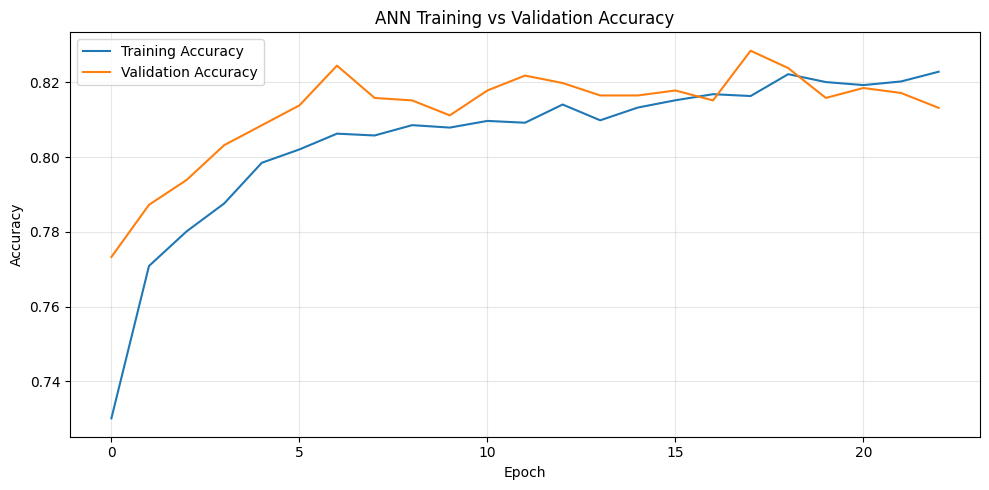

In [21]:

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ANN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:

import numpy as np

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Total epochs trained:", len(history.history["loss"]))
print("Best epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"]))
print(
    "Validation accuracy at best epoch:",
    history.history["val_accuracy"][best_epoch - 1]
)


Total epochs trained: 23
Best epoch: 16
Best validation loss: 0.4070512354373932
Validation accuracy at best epoch: 0.8178191781044006


In [ ]:

import numpy as np


y_prob_ann = model_ann.predict(
    X_ann_val_processed
).ravel()


y_pred_ann = (y_prob_ann >= 0.5).astype(int)

print("First 10 scores:")
print(y_prob_ann[:10])

print("\nFirst 10 predicted classes:")
print(y_pred_ann[:10])


47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
First 10 scores:
[6.7344964e-01 3.4069590e-04 2.2779700e-01 3.3909920e-01 7.4599522e-01
 6.0803217e-01 8.1484276e-01 8.7232316e-01 9.4993275e-01 9.4445723e-01]

First 10 predicted classes:
[1 0 0 0 1 1 1 1 1 1]


In [24]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

print("ANN Validation Accuracy:",
      accuracy_score(y_ann_val, y_pred_ann))

print("\nClassification Report:")
print(classification_report(
    y_ann_val,
    y_pred_ann,
    target_names=["False Positive", "Planet-like"],
    zero_division=0
))

print("ROC-AUC:",
      roc_auc_score(y_ann_val, y_prob_ann))


ANN Validation Accuracy: 0.8178191489361702

Classification Report:
                precision    recall  f1-score   support

False Positive       0.84      0.81      0.82       791
   Planet-like       0.79      0.83      0.81       713

      accuracy                           0.82      1504
     macro avg       0.82      0.82      0.82      1504
  weighted avg       0.82      0.82      0.82      1504

ROC-AUC: 0.9004952276930334


#model comparision 

In [25]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import pandas as pd

# Logistic Regression pipeline
lr_val_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# Random Forest pipeline
rf_val_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train on the same data used for ANN training
lr_val_model.fit(X_ann_train, y_ann_train)
rf_val_model.fit(X_ann_train, y_ann_train)

print("Both models trained successfully!")


Both models trained successfully!


In [26]:

results = []

models = {
    "Logistic Regression": lr_val_model,
    "Random Forest": rf_val_model
}

for name, model in models.items():
    predictions = model.predict(X_ann_val)
    probabilities = model.predict_proba(X_ann_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_ann_val, predictions),
        "F1-score": f1_score(y_ann_val, predictions),
        "ROC-AUC": roc_auc_score(y_ann_val, probabilities)
    })

# Add our already trained ANN results
results.append({
    "Model": "ANN",
    "Accuracy": accuracy_score(y_ann_val, y_pred_ann),
    "F1-score": f1_score(y_ann_val, y_pred_ann),
    "ROC-AUC": roc_auc_score(y_ann_val, y_prob_ann)
})

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4))


                 Model  Accuracy  F1-score  ROC-AUC
0  Logistic Regression    0.7600    0.7720   0.8218
1        Random Forest    0.8358    0.8262   0.9231
2                  ANN    0.8178    0.8121   0.9005


# Final Model Training and Export

#honestly i thought ANN would outperform the random forest but surprisingly random forest has more accuracy as well as ROC-AUC 


In [27]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train using our complete original training dataset
final_model.fit(X_train, y_train)

print("Final Random Forest trained successfully!")


Final Random Forest trained successfully!


In [28]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

# Final test predictions
y_pred_final = final_model.predict(X_test)

# Predicted class-1 scores
y_prob_final = final_model.predict_proba(X_test)[:, 1]

print("Final Test Accuracy:",
      accuracy_score(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    zero_division=0
))

print("Final Test ROC-AUC:",
      roc_auc_score(y_test, y_prob_final))


Final Test Accuracy: 0.8165089379600421

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.80      0.82       981
           1       0.80      0.84      0.82       921

    accuracy                           0.82      1902
   macro avg       0.82      0.82      0.82      1902
weighted avg       0.82      0.82      0.82      1902

Final Test ROC-AUC: 0.9023869370371478


In [29]:

import joblib
from pathlib import Path

# Create models folder
model_path = Path("D:/exoplanet_hunter/models/exoplanet_rf.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)

# Save complete preprocessing + model pipeline
joblib.dump(final_model, model_path)

print("Model saved at:", model_path.resolve())


Model saved at: D:\exoplanet_hunter\models\exoplanet_rf.joblib


In [31]:

import joblib
import numpy as np
from pathlib import Path

# Path to our saved ML pipeline
model_path = Path("../models/exoplanet_rf.joblib")

# Load the saved model
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print(loaded_model)


Model loaded successfully!
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])


In [32]:

# Predict using original trained model
original_predictions = final_model.predict(X_test)

# Predict using loaded model
loaded_predictions = loaded_model.predict(X_test)

# Compare both outputs
print(
    "Predictions identical:",
    np.array_equal(
        original_predictions,
        loaded_predictions
    )
)


Predictions identical: True
